# Project SakAI — Crop classification, step by step

**Our question:** Can a model trained on European fields identify **carrot, cabbage, and potato** in separate test campaigns?

Each part explains what we did, why we did it, and how to read a saved example. The tables and figures are already displayed. The code cells only read saved files. The walkthrough ends with the external study package.

**What we found:** On matching test fields, the fixed calendar model scored higher on JECAM. The green-up model scored higher when JECAM was pooled with the three reported supplements. The growing region and crop mix mattered.

# Part 0 — The big picture

**Find labelled fields → clean their satellite images → turn the images into numbers → train → test on separate fields → explain the errors → package the results.**

| Term | Plain meaning |
| --- | --- |
| **Parcel** | A field or a group of pieces of the same field. We count it once when scoring. |
| **Pixel** | One square of the satellite grid. Several usable pixels can describe a field. |
| **Development** | The training fields used to fit or tune, plus separate locked validation fields used to check the model. |
| **External test** | Fields held apart from development and used to check how the frozen model transfers. |
| **Full / matched** | Full lets each window use its own eligible fields. Matched uses the same fields and pixel locations for both windows. |

**Why split the work this way?** We need fields the model can learn from and separate fields that show how well that learning carries over. In the matched study, **199 fields** were used for training, **69** for locked validation, and **83** for the primary external JECAM test.

In [1]:
# Locate the checkout and read only the final saved study outputs.
import csv
import json
from pathlib import Path
import sys

from IPython.display import Markdown, display

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file()), None)
if root is None:
    raise RuntimeError("Open the notebook inside the project checkout.")
sys.path.insert(0, str(root / "src"))
outputs = root / "pipeline_outputs"
training = outputs / "training/run_fa40f5d6bb31"
testing = outputs / "testing"
run = "run_81a0d0a2812e"
batch1 = testing / f"{run}_batch1_revised"
batch2 = testing / f"{run}_batch2"
batch3 = testing / f"{run}_batch3"
followups = testing / f"{run}_transfer_followups"
batch4 = testing / f"{run}_batch4/study_manifest.json"
preprocessing = outputs / "preprocessing/external_xxu0iz4o"
usable = preprocessing / "features/usable_samples.csv"
models = ("fixed_full", "aligned_full", "fixed_matched", "aligned_matched")
crops = ("carrot", "cabbage", "potato")

def read_csv(path):
    with path.open(newline="", encoding="utf-8") as stream:
        return list(csv.DictReader(stream))

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def table(headers, rows):
    def line(values):
        return "| " + " | ".join(map(str, values)) + " |"
    display(Markdown("\n".join([line(headers), line(["---"] * len(headers)), *map(line, rows)])))

def model_name(name):
    return name.replace("_", "-").capitalize()

def f1(value):
    return f"{float(value):.3f}" if value not in ("", None) else "—"

def ci(row):
    return f"{f1(row['estimate'])} [{f1(row['ci_low'])}, {f1(row['ci_high'])}]"

def support(row):
    return f"{int(row['support']):,} / {int(row['usable_pixels']):,}"

# Part 1 — Find fields with known crops

| Collection notebook | What we used it for | Why it matters |
| --- | --- | --- |
| 01 External reference audit | Check candidate sources and their original crop codes. | Different datasets use different names and codes for the same crop. |
| 02 Sen4AgriNet, 03 FranceCrops, 04 EuroCrops | Collect European development references. | These give the model known examples of carrot, cabbage, and potato. |
| 05 CropHarvest | Reserve JECAM as the primary test and keep the other CropHarvest campaigns separate. | JECAM provides all three crops on independent test fields. Its Madagascar site supplies the closest documented highland comparison. Senegal adds cabbage. |
| 06 California and 07 Denmark | Add California carrot and Denmark cabbage tests. | The model is checked in more than one growing region. The separate CropHarvest potato supplement adds Île-de-France and Réunion. |
| 08 Dataset summary | Record sources, selected fields, and which collection jobs finished. | Selecting a field is the first step. Its imagery still needs to pass quality and date checks. |

**Example.** FranceCrops supplied all **50 matched training cabbage fields**. The map and tables below show that the crop samples are spread unevenly across sources and locations.

The revised report retains California carrot, Denmark cabbage, and non-JECAM potato. That scope changed after score review. The original evaluation also retains the non-JECAM cabbage and carrot rows.

[Collection notebooks](data_collection/README.md) · [Final dataset register and crop codes](../docs/classification_dataset_register.md)

## What each dataset supplied

| Dataset | Imagery in or used by the source | Crops used in our study |
| --- | --- | --- |
| Sen4AgriNet | Multi-date Sentinel-2 imagery | Carrot, potato |
| FranceCrops | Sentinel-2 Level-2A time series | Cabbage, potato |
| EuroCrops | Parcel declarations and boundaries in the release used here | Carrot |
| CropHarvest JECAM | Sentinel-2 and Sentinel-1 in the wider CropHarvest imagery package | Carrot, cabbage, potato |
| CropHarvest non-JECAM | Sentinel-2 and Sentinel-1 in the wider CropHarvest imagery package | Potato in the revised test scope |
| California DWR | Crop survey maps informed by aerial imagery, Landsat, and Sentinel | Carrot |
| Denmark Marker | Declared field boundaries and crop codes in the release used here | White and red cabbage |

**From these sources to one imagery pipeline.** We kept the crop labels, field locations, and reference dates. We then used those references to pull imagery from the same Sentinel-2 Level-2A archive. Applying the same cloud mask, grid, scaling, and half-month compositing gave all training and test parcels comparable inputs.

[Sen4AgriNet benchmark](https://arxiv.org/abs/2204.00951) · [FranceCrops dataset](https://huggingface.co/datasets/saget-antoine/francecrops) · [EuroCrops parcel data](https://essd.copernicus.org/articles/18/4075/2026/essd-18-4075-2026.html) · [CropHarvest benchmark](https://github.com/nasaharvest/cropharvest) · [California DWR survey methods](https://resources.ca.gov/-/media/DWR-Website/Web-Pages/Programs/Water-Use-And-Efficiency/Land-And-Water-Use/Land-Use-Surveys/Files/Land-Use-Program-Frequently-Asked-Questions.pdf) · [Denmark Marker release](https://landbrugsgeodata.fvm.dk/) · [Project collection rules](../docs/collection.md)

## Why use the same Sentinel-2 inputs everywhere?

Sentinel-2 revisits the same fields repeatedly, which lets us build a sequence through the growing season. Its green, red, near-infrared, red-edge, and shortwave-infrared bands support the reflectance and index features used here. The harmonized **Level-2A surface-reflectance** collection gives one consistent starting product across the training and test regions. [Sentinel-2 Earth Engine catalog](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED)

**Why standardize the processing too?** Even two Sentinel-2 datasets can use different masks, band scaling, grids, or averaging periods. Using the same cloud screening, 10 m output grid, reflectance scaling, and half-month compositing reduces processing differences the classifier could pick up. Fixed and green-up-aligned models still use different dates by design. Part 2 walks through the common processing settings. [Project imagery and feature rules](../docs/methodology.md#candidate-sampling-and-imagery)

### Settings we used and why

| Setting | What we used | Why |
| --- | --- | --- |
| Satellite product | Harmonized Sentinel-2 Level-2A surface reflectance | Gives training and test fields the same starting product and measurement scale. |
| Cloud-probability screening | Keep values **below 40** on the 0–100 cloud-probability scale. Reject pixels at **40 or above** and require a valid match to the acquisition. | Screens out likely clouds before they can distort vegetation signals. Requiring a match prevents missing cloud information from counting as clear. |
| Scene classification and valid data | Exclude SCL classes **0, 1, 3, 8, 9, 10, and 11**, covering missing or defective data, cloud shadow, cloud, cirrus, and snow or ice. Also require valid edges and support in all archived spectral bands. | The cloud score alone cannot catch every unusable pixel, including cloud shadow or invalid scene edges. |
| Spatial grid | A **10 m output grid**, with B3, B4 and B8 on their native 10 m grid. Align 20 m B5 and B11 with bilinear interpolation and use nearest-neighbor for masks. | The bands must refer to the same location for the indices to make sense. Reflectance is continuous, while masks must retain their categories. |
| Reflectance scaling | Multiply stored reflectance by **0.0001** before calculating indices. Leave observation counts in their original units. | Puts the bands on the reflectance scale used by formulas such as SAVI, and keeps a clear-date count interpretable as a count. |
| Time compositing | Mosaic same-date observations. Take the median of valid dates for **days 1–15** and **day 16 through month end**. | Counts overlapping acquisitions on one date once and reduces the effect of unusually bright or dark observations. |
| Interval and pixel eligibility | Require **at least 80% valid selected pixels** for a region’s half-month to pass. A retained model pixel must have valid predictors across **all eight bins** of its four-month window. | The region threshold screens intervals with patchy coverage. The pixel rule gives every retained input a complete sequence. |

The cloud cutoff and coverage threshold are fixed settings for this study. Part 2 shows how many intervals passed and how many pixel-dates were flagged for cloud or shadow. [Project preprocessing rules](../docs/methodology.md#candidate-sampling-and-imagery) · [Saved quality audit](../pipeline_outputs/preprocessing/external_xxu0iz4o/quality/quality_counts.csv)


## What runs in Earth Engine and what we reuse locally

**Select reference pixels locally → submit Earth Engine batch jobs → retrieve and verify finished exports → archive them locally → reuse them for feature engineering.**

| Where | What happens | Why this saves work |
| --- | --- | --- |
| **Local setup** | Prepare field IDs, selected interior pixels, and the batch plan. Save job IDs and progress in a ledger. | A resumed session can find the same fields and jobs. |
| **Google Earth Engine (GEE)** | Match acquisitions and cloud-probability data, mask invalid observations, align bands, mosaic by date, and form the half-month medians. Export selected-pixel measurements and timing summaries through batch jobs. | The cloud does the heavy image work and returns the measurements needed at the selected locations. Submitted batch jobs can continue after the laptop disconnects. |
| **Temporary GEE storage** | Finished job outputs wait in export assets. The collector removes the temporary assets after it has retrieved and verified the results. | Collection can resume later using the saved task IDs. |
| **Local archive and analysis** | Keep the verified annual TIFFs, selected-pixel tables, timing summaries, masks, and receipts. Later notebooks read them to select windows, build indices and features, and fit or evaluate models. | The annual archive can support another four-month window without repeating cloud masking or compositing. A change to the bands, masks, or compositing rules can require new processing. |

**The distinction:** Earth Engine runs the jobs and holds the temporary export results. The saved local archive is what we keep and reuse. The laptop needs a connection to submit jobs and collect the results. [Earth Engine batch processing](https://developers.google.com/earth-engine/guides/processing_environments) · [Saved imagery formats and cache reuse](../docs/reference/transport.md)

## From labels to collection batches

The source audit preserves native crop codes and maps them into three classes. Examples are **231** for Sen4AgriNet carrot, **CHU** for FranceCrops cabbage, **408/418** for Danish head cabbage, **T6** for California carrot and **PTC** for FranceCrops table potato. The exact crosswalk also covers Dutch carrot, JECAM field labels, and consumption and starch potato.

Each batch keeps its source revision, reference year, parcel IDs, eligible interior locations, and imagery receipt. Same-parcel fragments share an ID. FranceCrops, EuroCrops, and CropHarvest use a 10 m inward buffer to keep samples away from field edges. Sen4AgriNet uses its existing crop mask with no extra inward buffer. The satellite image-edge check in the imagery settings serves a separate purpose. It removes invalid image pixels. The collector can resume from its saved state, or the preprocessing workflow can start from a teammate’s imported imagery handoff.

**Why retain source codes and batch receipts?** They preserve the link from a reported crop back to its original evidence, and let later runs reuse completed collection work. Survey dates and annual declarations provide different kinds of timing evidence.

**What to look at.** These are European candidate parcels in the saved pre-window inventory. Final usable support is reported later.

![Illustration of a field with a 10-metre strip excluded around its boundary](assets/walkthrough_field_buffer.png)

[Exact label crosswalk](../docs/classification_dataset_register.md) · [Collection and handoff rules](../docs/workflow.md#choose-the-input-route)

In [2]:
profile = read_csv(preprocessing / "quality/reference_profile.csv")
names = ("Sen4AgriNet", "FranceCrops", "EuroCrops")
sources = ("sen4agrinet", "francecrops", "eurocrops")
table(("Source", "Candidate training parcels", "Candidate validation parcels"),
      [[name, *(sum(int(r["parcels"]) for r in profile if (r["source"], r["partition"]) == (source, split))
                for split in ("train", "validation"))]
       for name, source in zip(names, sources)])

| Source | Candidate training parcels | Candidate validation parcels |
| --- | --- | --- |
| Sen4AgriNet | 880 | 321 |
| FranceCrops | 1157 | 362 |
| EuroCrops | 1229 | 401 |

## Where the matched parcels are

Development parcels are on mainland Europe. The external test covers separate campaigns in Europe, North America, Madagascar, Senegal, and Réunion. The tables count **unique parcels** in the matched cohorts, so the fixed and aligned models share these counts. We take the locations from the saved field records.

**Why show geography by crop?** A crop can be concentrated in one place. For example, all development cabbage came from FranceCrops, and Madagascar contributes three of the eleven matched JECAM cabbage parcels. This matters when discussing whether an error reflects the crop, location, or both.

[Source evidence and label crosswalk](../docs/classification_dataset_register.md) · [Saved external parcel evidence](../pipeline_outputs/testing/run_81a0d0a2812e_batch3/parcel_diagnostics.csv)

In [3]:
from collections import Counter

development = read_json(outputs / "development_error_review_2026-11-19/parcel_diagnostics.json")
sites = {"ES": "Spain", "FR": "France", "NL": "Netherlands"}
stage_labels = {"geographic_cv": "Training", "locked_validation": "Locked validation"}
dev_counts = Counter()
for row in development:
    if row["cohort"] == "fixed_matched" and row["stage"] in stage_labels:
        country = row["partition_group"].split("|")[1]
        dev_counts[row["stage"], row["source"], sites[country], row["crop"]] += 1

table(("Development split", "Source", "Country", "Carrot", "Cabbage", "Potato"),
      [[stage_labels[stage], names[sources.index(source)], country,
        *(dev_counts[stage, source, country, crop] for crop in crops)]
       for stage in stage_labels
       for source, country in sorted({(s, c) for st, s, c, _ in dev_counts if st == stage})])
assert sum(dev_counts.values()) == 199 + 69

external_sites = (
    ("JECAM", "jecam", "Madagascar", "Madagascar"),
    ("JECAM", "jecam", "Senegal", "Senegal"),
    ("California carrot", "california_dwr_carrot_2023_v1", "US", "California, USA"),
    ("Denmark cabbage", "denmark_marker_cabbage_2023_v1", "DK", "Denmark"),
    ("Non-JECAM potato", "non_jecam_carrot_potato_supplement_v1", "ile-de-france", "Île-de-France"),
    ("Non-JECAM potato", "non_jecam_carrot_potato_supplement_v1", "reunion-france", "Réunion"),
)
external_counts = Counter((row["population"], row["source_site"], row["reference_crop"])
                          for row in read_csv(batch3 / "parcel_diagnostics.csv")
                          if row["model"] == "fixed_matched")
site_rows = [[label, geography, *(external_counts[scope, site, crop] for crop in crops)]
             for label, scope, site, geography in external_sites]
assert sum(sum(row[2:]) for row in site_rows) == sum(external_counts.values()) == 175
table(("External campaign", "Geography", "Carrot", "Cabbage", "Potato"), site_rows)

| Development split | Source | Country | Carrot | Cabbage | Potato |
| --- | --- | --- | --- | --- | --- |
| Training | EuroCrops | Netherlands | 47 | 0 | 0 |
| Training | FranceCrops | France | 0 | 50 | 11 |
| Training | Sen4AgriNet | France | 7 | 0 | 12 |
| Training | Sen4AgriNet | Spain | 18 | 0 | 54 |
| Locked validation | EuroCrops | Netherlands | 11 | 0 | 0 |
| Locked validation | FranceCrops | France | 0 | 13 | 8 |
| Locked validation | Sen4AgriNet | France | 2 | 0 | 6 |
| Locked validation | Sen4AgriNet | Spain | 4 | 0 | 25 |

| External campaign | Geography | Carrot | Cabbage | Potato |
| --- | --- | --- | --- | --- |
| JECAM | Madagascar | 37 | 3 | 35 |
| JECAM | Senegal | 0 | 8 | 0 |
| California carrot | California, USA | 62 | 0 | 0 |
| Denmark cabbage | Denmark | 0 | 15 | 0 |
| Non-JECAM potato | Île-de-France | 0 | 0 | 9 |
| Non-JECAM potato | Réunion | 0 | 0 | 6 |

## Map of the training and external test locations

The overview shows the primary JECAM sites and the three reported supplemental campaigns. The Europe panel separates the Spanish, French and Dutch development locations from Denmark and Île-de-France. Hollow circles show locked validation. A hollow circle and a solid dot can share a one-degree cell while referring to different field parcels.

**How to read the marks.** Each marker is the center of an occupied one-degree site cell in the matched data. Several fields can share a mark. Use the tables above for parcel counts and the map for geographic context.

[Cartographic background from Natural Earth, 1:110m](https://www.naturalearthdata.com/downloads/110m-cultural-vectors/110m-admin-0-countries/)

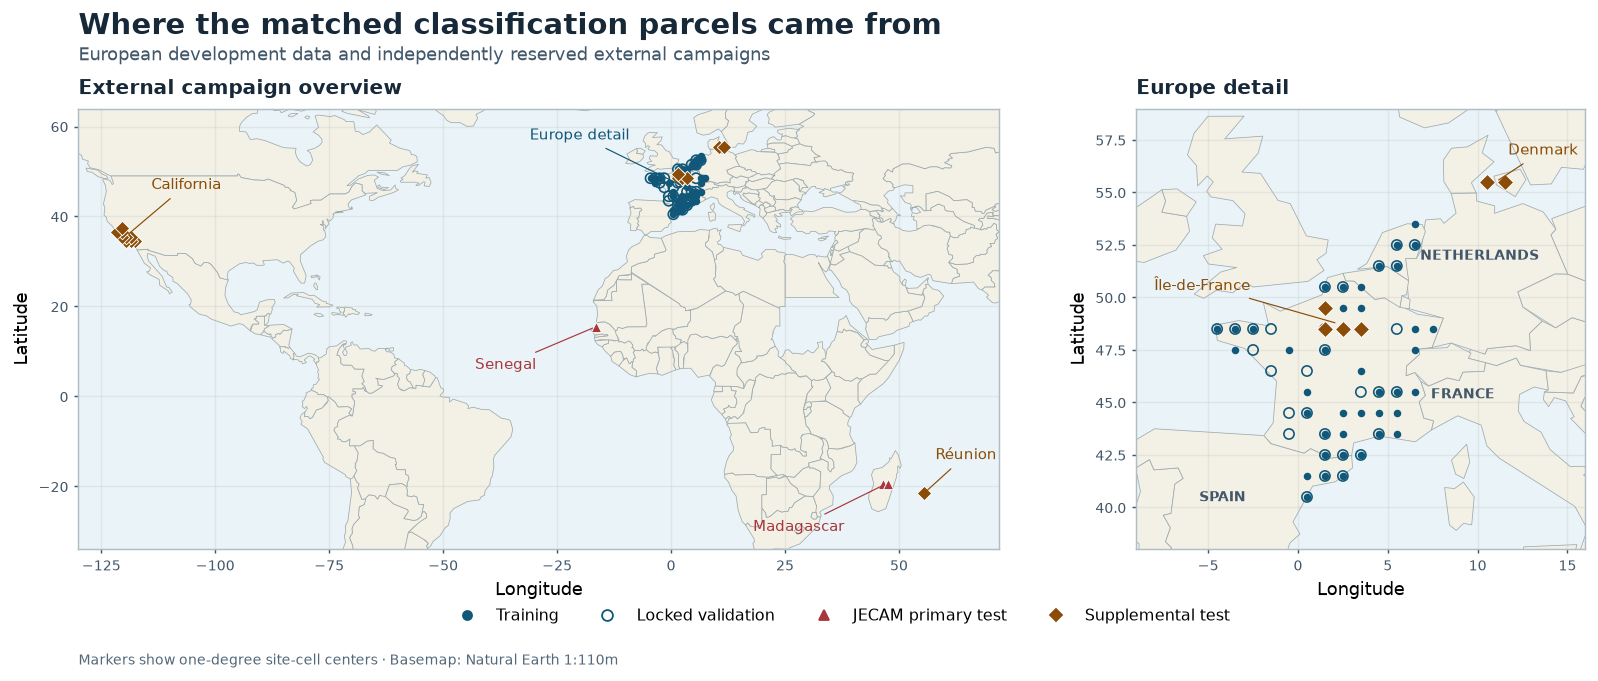

In [4]:
# Map the same matched populations counted in the tables above.
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.lines import Line2D

training_cells = {r["site_cell"] for r in development
                  if r["cohort"] == "fixed_matched" and r["stage"] == "geographic_cv"}
validation_cells = {r["site_cell"] for r in development
                    if r["cohort"] == "fixed_matched" and r["stage"] == "locked_validation"}
test_records = [r for r in read_csv(batch3 / "parcel_diagnostics.csv") if r["model"] == "fixed_matched"]
test_cells = {site: {grid for row in test_records if (row["population"], row["source_site"]) == (scope, site)
                     for grid in row["site_cell"].split(";")}
              for _, scope, site, _ in external_sites}

def centers(site_cells):
    return [(int(lon) + 0.5, int(lat) + 0.5)
            for lat, lon in (grid.split(",") for grid in sorted(site_cells))]

def plot_marks(ax, site_cells, **options):
    lon, lat = zip(*centers(site_cells))
    ax.scatter(lon, lat, **options)

base = read_json(root / "notebooks/assets/classification_basemap.geojson")
outlines = []
for feature in base["features"]:
    geometry = feature["geometry"]
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    outlines.extend(polygon[0] for polygon in polygons)

train_color, primary_color, supplement_color = "#105779", "#a7373c", "#8a4c06"
fig, (overview, europe) = plt.subplots(1, 2, figsize=(12.6, 5.3),
                                      gridspec_kw={"width_ratios": [2.05, 1]})
fig.subplots_adjust(left=0.065, right=0.985, top=0.83, bottom=0.19, wspace=0.20)
fig.suptitle("Where the matched classification parcels came from",
             x=0.065, y=0.97, ha="left", fontsize=16, fontweight="bold", color="#172838")
fig.text(0.065, 0.90, "European development data and independently reserved external campaigns",
         fontsize=10, color="#42576a")
for ax, xlim, ylim, title in [
    (overview, (-130, 72), (-34, 64), "External campaign overview"),
    (europe, (-9, 16), (38, 59), "Europe detail"),
]:
    ax.set_facecolor("#eaf3f7")
    ax.add_collection(PolyCollection(outlines, facecolor="#f3f0e6", edgecolor="#9caaad",
                                     linewidth=0.42, zorder=1))
    ax.set(xlim=xlim, ylim=ylim, xlabel="Longitude", ylabel="Latitude")
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold", color="#172838", pad=8)
    ax.grid(alpha=0.20, zorder=0)
    ax.tick_params(labelsize=8, length=2, colors="#42576a")
    for spine in ax.spines.values():
        spine.set_color("#afbec6")

    plot_marks(ax, validation_cells, facecolors="none", edgecolors=train_color, s=32, linewidths=0.9, zorder=3)
    plot_marks(ax, training_cells, color=train_color, marker="o", s=10, zorder=4)
    for _, scope, site, _ in external_sites:
        primary = scope == "jecam"
        plot_marks(ax, test_cells[site], marker="^" if primary else "D",
                   color=primary_color if primary else supplement_color, edgecolors="white",
                   linewidths=0.5, s=40 if ax is europe else 32, zorder=5)

def label_site(ax, name, grids, label_position, color):
    points = centers(grids)
    x = sum(lon for lon, _ in points) / len(points)
    y = sum(lat for _, lat in points) / len(points)
    ax.annotate(name, (x, y), xytext=label_position, textcoords="data", color=color,
                fontsize=8.5, fontweight="medium", ha="left", va="center",
                arrowprops={"arrowstyle": "-", "color": color, "linewidth": 0.65}, zorder=6)

label_site(overview, "California", test_cells["US"], (-114, 47), supplement_color)
label_site(overview, "Senegal", test_cells["Senegal"], (-43, 7), primary_color)
label_site(overview, "Madagascar", test_cells["Madagascar"], (18, -29), primary_color)
label_site(overview, "Réunion", test_cells["reunion-france"], (58, -13), supplement_color)
label_site(overview, "Europe detail", training_cells, (-31, 58), train_color)
label_site(europe, "Denmark", test_cells["DK"], (11.7, 57), supplement_color)
label_site(europe, "Île-de-France", test_cells["ile-de-france"], (-8, 50.6), supplement_color)
europe.text(-5.5, 40.3, "SPAIN", fontsize=8, color="#42576a", fontweight="bold")
europe.text(7.4, 45.2, "FRANCE", fontsize=8, color="#42576a", fontweight="bold")
europe.text(6.8, 51.8, "NETHERLANDS", fontsize=7.5, color="#42576a", fontweight="bold")
handles = [
    Line2D([], [], marker="o", linestyle="none", color=train_color, markersize=5, label="Training"),
    Line2D([], [], marker="o", linestyle="none", markerfacecolor="none", markeredgecolor=train_color,
           markersize=6, label="Locked validation"),
    Line2D([], [], marker="^", linestyle="none", color=primary_color, markersize=6, label="JECAM primary test"),
    Line2D([], [], marker="D", linestyle="none", color=supplement_color, markersize=5, label="Supplemental test"),
]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.53, 0.06), ncol=4, frameon=False, fontsize=9)
fig.text(0.065, 0.023, "Markers show one-degree site-cell centers · Basemap: Natural Earth 1:110m",
         fontsize=8, color="#536879")
display(fig)
plt.close(fig)

# Part 2 — Clean the satellite images and check what we can see

We need a clear view of the same ground over time. **Preprocessing 01** checks the saved Sentinel-2 imagery and records which half-months are usable.

### 1. Check that training and test fields are separate

Compare the original field outlines. Keep overlapping ground out of the external comparison so the model is tested on fields it did not see during training.

### 2. Clear away clouds, shadows, and bad data

Check each satellite view before combining it with others. Keep pixels with a cloud score **below 40 out of 100** and a matching cloud record. Also remove pixels flagged as cloud shadow, cirrus, snow or ice, or invalid data. These can make a healthy crop look brighter or darker than it really is.

### 3. Line up the bands on the same 10 m grid

A **band** measures one part of the light reflected from the ground. Some bands use squares **10 m** wide. B5 and B11 use squares **20 m** wide. We place them on the same 10 m grid so the values used together refer to the same patch of ground. To align the 20 m bands, we estimate their values using nearby measurements. For the yes/no quality masks, we use the nearest mask value. A finer grid does not add detail to the original 20 m measurements.

### 4. Make one image for each half-month

Join overlapping images taken on the same date first. For each pixel, use the **middle value (median)** from its clear observations during days **1–15** or **16 through month-end**. This reduces the effect of unusually bright or dark observations. We save the number of clear dates too, so we can tell whether a value came from one clear day or several.

### 5. Check how much of the area is visible — the 80% rule

Suppose we selected **100 pixels** in a region. If **85** have usable values in that half-month, the region passes because at least 80 are usable. If only **70** have usable values, it fails. This check is about **the region in one half-month**.

### 6. Follow the same pixel through time — the eight-bin rule

A **bin** is one half-month. A four-month window has **eight bins**. Even if the region passes the 80% rule in every half-month, different pixels may be missing on different dates. A pixel that has usable values in seven bins and is missing bin 6 stays out of the model. This check is about **one pixel across four months**.

[Preprocessing 01](preprocessing/01_imagery_quality.ipynb) · [Quality receipt](../pipeline_outputs/preprocessing/external_xxu0iz4o/quality/quality_stage_receipt.json) · [Saved quality counts](../pipeline_outputs/preprocessing/external_xxu0iz4o/quality/quality_counts.csv)

In [5]:
quality = read_csv(preprocessing / "quality/quality_counts.csv")
masks = read_csv(batch3 / "archive_mask_coverage.csv")
table(("Split", "Audited tile intervals", "Quality-pass tile intervals", "Saved region-bins lacking pre-mask counts"),
      [[split.title(),
        *(f"{sum(int(r[key]) for r in quality if r['partition'] == split):,}"
          for key in ("audited_tile_intervals", "quality_pass_tile_intervals")),
        f"{sum(int(r['region_bins_without_pre_mask_counts']) for r in masks if r['partition'] == split):,}"]
       for split in ("train", "validation", "test")])

| Split | Audited tile intervals | Quality-pass tile intervals | Saved region-bins lacking pre-mask counts |
| --- | --- | --- | --- |
| Train | 106,008 | 80,667 | 9,168 |
| Validation | 35,424 | 27,152 | 2,496 |
| Test | 22,824 | 18,219 | 0 |

## How to read the missing imagery and cloud counts

The table below counts half-months in the **annual imagery archive**, before we choose four months or limit how many pixels a field contributes. A **region-bin** is one saved field region or fragment in one half-month.

| What the table counts | What it means |
| --- | --- |
| **Missing audit row** | We expected a half-month record but found none in the archive. |
| **Zero usable pixels** | There was a record, and none of the selected pixels had a usable value. Denmark had every expected record, and **606 of 2,520** region–half-months still had zero usable pixels. |
| **Some usable, below gate** | There were usable pixels, but fewer than 80% of the selected pixels were usable in that region and half-month. |
| **Cloud or shadow loss** | We count individual views blocked by cloud or shadow. If a pixel was cloudy on **May 3** and clear on **May 11**, that is one lost view. The May 11 measurement can still go into the May 1–15 image. |

**Why the numbers differ.** The 80% rule counts usable pixels in a finished half-month image. The eight-bin rule follows one pixel through all eight images. Cloud loss counts **each pixel on each acquisition date** before the half-month image is made. Its percentage uses only views with recorded pre-mask support. Some older development records lack that information, so their loss counts are unavailable.

[Saved imagery coverage by campaign and crop](../pipeline_outputs/testing/run_81a0d0a2812e_batch3/imagery_coverage.csv) · [Pre-mask count availability by source and split](../pipeline_outputs/testing/run_81a0d0a2812e_batch3/archive_mask_coverage.csv)

In [6]:
from collections import defaultdict

from crop_pipeline.common import interval_bins
from crop_pipeline.training.external_report import retained_reference

audit = read_json(preprocessing / "quality/quality.json")
regions_by_campaign = defaultdict(dict)
for feature in audit["regions"]:
    row = feature["properties"]
    scope = row.get("test_cohort", "jecam")
    if row["partition"] == "test" and retained_reference(scope, row["crop"]):
        regions_by_campaign[scope][row["fragment_id"]] = int(row["year"])
audit_rows = defaultdict(dict)
for row in audit["quality_rows"]:
    saved = audit_rows[row["region_id"]]
    assert row["name"] not in saved
    saved[row["name"]] = row

campaigns = (
    ("JECAM", "jecam"),
    ("California carrot", "california_dwr_carrot_2023_v1"),
    ("Denmark cabbage", "denmark_marker_cabbage_2023_v1"),
    ("Non-JECAM potato", "non_jecam_carrot_potato_supplement_v1"),
)
loss_rows = []
for label, scope in campaigns:
    missing = 0
    saved_bins = []
    for region, year in regions_by_campaign[scope].items():
        expected = {entry["name"] for entry in interval_bins(year)}
        saved = audit_rows[region]
        missing += len(expected - saved.keys())
        saved_bins.extend(saved[name] for name in expected & saved.keys())
    empty = sum(r["valid_pixels"] == 0 for r in saved_bins)
    below = sum(r["status"] == "low_coverage" and r["valid_pixels"] > 0 for r in saved_bins)
    known = [r for r in saved_bins if r["pre_mask_count"] is not None and r["cloud_shadow_count"] is not None]
    supported = sum(r["pre_mask_count"] for r in known)
    rejected = sum(r["cloud_shadow_count"] for r in known)
    assert 0 <= rejected <= supported
    loss_rows.append([label, f"{len(saved_bins):,}", f"{missing:,}", f"{empty:,}", f"{below:,}",
                      f"{rejected:,} / {supported:,} ({rejected / supported:.1%})" if supported else "Unavailable"])
table(("External campaign", "Saved region-bins", "Missing audit rows", "Zero usable pixels",
       "Some usable, below gate", "Cloud/shadow rejected / supported pixel-dates"), loss_rows)
del audit, audit_rows

| External campaign | Saved region-bins | Missing audit rows | Zero usable pixels | Some usable, below gate | Cloud/shadow rejected / supported pixel-dates |
| --- | --- | --- | --- | --- | --- |
| JECAM | 5,448 | 0 | 560 | 39 | 54,806 / 179,266 (30.6%) |
| California carrot | 4,224 | 0 | 184 | 49 | 4,232,956 / 14,495,902 (29.2%) |
| Denmark cabbage | 2,520 | 0 | 606 | 303 | 2,609,246 / 3,552,909 (73.4%) |
| Non-JECAM potato | 8,880 | 0 | 1,646 | 840 | 6,864,729 / 10,641,796 (64.5%) |

# Part 3 — Choose the four months we use for each field

**Preprocessing 02** starts with the checked imagery from Part 2. It chooses four months at a time. Both methods give the model **eight half-months**.

### 1. Use the same calendar dates — fixed window

For every field, use **May 1 through August 31** of its reference year. We recorded the end as September 1 because September 1 itself is outside the window.

**Why May through August?** The project fixed these four complete calendar months as the reference period. This gives every field a predictable eight half-months, with the same length as the green-up-aligned window. Holding the length fixed lets us ask whether adjusting the **start date** to each field’s growth helps. The project records May–August as a design choice. They do not identify it as the best growing period for each crop or region. [Project design](../docs/project_design.md#what-we-compare) · [Research basis and limits](../docs/research_basis.md#project-choices-to-report-explicitly)

### 2. Follow the rise in vegetation — green-up-aligned window

Look at how green the field appears on clear dates. Look for observations before the rise and several later observations that show the rise continued. If the rise is supported, start the four-month window at the beginning of the selected month. If several windows qualify, use the **earliest one with at least one pixel usable in all eight half-months**. If a window crosses into the next year, it needs imagery from that year as well.

**Why use it?** Crops in different places can start growing in different months. Aligning to a sustained rise lets us test whether similar stages of growth make the crops easier to recognize. A rise in greenness suggests growth. The reference label supplies the crop identity.

### What counts as a supported rise?

- We look for at least **two usable observations in the 30 days before** the rise. The observations around the start must be no more than **20 days apart** and fall within one month for automatic qualification.
- In the following **30 days**, at least **two later observations** must be above the rise threshold, and at least **75%** of usable confirmation observations must be above it. The observations that confirm growth can be no more than **20 days apart**.
- We check that **NDRE**, another vegetation measure, also rises. We try rise thresholds of **15%, 20%, and 25%** of the vegetation signal’s seasonal change to check that they point to the same cycle. We record changes in **NDMI**, a moisture-sensitive measure, as extra evidence.

**Why ask for several checks?** One unusually green image could give a false start. We keep a record of the windows considered and which ones qualified so we can trace where fields were lost.

### Why compare both methods on the same fields?

A higher score could come from a better window or from testing on an easier set of fields. In the **matched** comparison, both methods use the same fields and pixel locations. The **full** models show the coverage each method can achieve with its own eligible fields.

[Preprocessing 02](preprocessing/02_window_selection.ipynb) · [Detailed timing rules](../docs/methodology.md#automatic-timing-assessment) · [Cycle selection audit](../pipeline_outputs/preprocessing/external_xxu0iz4o/windows/seasons/cycle_selection_audit.csv)

In [7]:
# Follow one JECAM pixel through both frozen windows.
from crop_pipeline.sources.sampling import pixel_location

features = read_json(testing / run / "features_test.json")["rows"]
fixed_pixel = next(r for r in features["fixed_matched"] if r["test_cohort"] == "jecam")
aligned_pixel = next(r for r in features["aligned_matched"]
                     if r["partition_group"] == fixed_pixel["partition_group"]
                     and pixel_location(r) == pixel_location(fixed_pixel))
example = (("Fixed-matched", fixed_pixel), ("Aligned-matched", aligned_pixel))
parcel_label = fixed_pixel["partition_group"].replace("|", " / ")
display(Markdown(f"**One saved reference parcel and pixel:** {parcel_label} · {fixed_pixel['crop']}"))
table(("Recipe", "Start", "Exclusive end", "Clear dates in bins 1–8"),
      [[label, row["window_start"], row["window_end"],
        ", ".join(str(row[f"bin_{i:02d}_clear_count"]) for i in range(1, 9))]
       for label, row in example])
del features

**One saved reference parcel and pixel:** cropharvest / jecam / 2019 / jecam:7450 · carrot

| Recipe | Start | Exclusive end | Clear dates in bins 1–8 |
| --- | --- | --- | --- |
| Fixed-matched | 2019-05-01 | 2019-09-01 | 3, 4, 1, 3, 4, 5, 5, 5 |
| Aligned-matched | 2019-02-01 | 2019-06-01 | 3, 1, 3, 6, 5, 3, 3, 4 |

**What the example shows.** This is the same JECAM carrot field and the same pixel in both rows. The fixed method used **May–August 2019**. The green-up method chose **February–May 2019**. The field record is dated **April 5, 2019**, so it falls inside the aligned window and before the fixed window. Both rows have at least one clear observation in each of their eight half-months.

**Why that matters.** The aligned window includes the date the carrot was recorded. That supports the timing comparison for this field. We still use the external test scores to judge how well each window works across crops and fields.

[Saved field reference audit](../pipeline_outputs/test_audit_2026-11-19/parcel_audit.json)

![Timeline showing the April 5 crop observation in the aligned window and before the fixed window](assets/walkthrough_window_dates.png)


# Part 4 — Turn the satellite images into model inputs

A **feature** is a number the model uses to make a prediction. Here, it is either a band measurement or a number calculated from two bands. **Preprocessing 03** turns each eligible pixel’s four months of imagery into one ordered row of numbers. It saves separate development and test tables, a receipt, and the usable parcel and pixel counts.

### 1. Read five measurements of reflected light

A **band** measures how much light the ground reflects in a particular range. A higher value means more light was reflected in that range. We multiply the stored band values by **0.0001** to get surface reflectance before calculating indices.

| Band | What it measures | Why we kept it |
| --- | --- | --- |
| **B3 · Green** | Visible green light. | Gives the model a direct measure of green reflectance, which can vary with vegetation and exposed ground. |
| **B4 · Red** | Visible red light, which chlorophyll tends to absorb. | Comparing red with near-infrared helps reveal green vegetation. B4 is used in NDVI and SAVI. |
| **B5 · Red edge** | Light just beyond visible red, where plant reflectance rises toward near-infrared. | Adds evidence about the canopy and leaf chlorophyll. B5 is used in NDRE. |
| **B8 · Near-infrared (NIR)** | Light beyond visible red that healthy leaf tissue typically reflects strongly. | Helps describe vegetation cover and canopy structure. B8 is used in all four indices. |
| **B11 · Shortwave infrared (SWIR)** | A longer wavelength of light that responds to water in vegetation and to soil conditions. | Adds a moisture-sensitive signal and is used in NDMI. |

**Why keep the band measurements too?** The indices summarize contrasts between bands. Keeping the individual measurements lets the forest also use their brightness and combinations across time. Part 7 compares bands only, indices only, and both together. [Sentinel-2 band definitions and scale](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED)

### 2. Combine bands into four vegetation indicators

An **index** compares two bands in one number. The first three use the difference divided by the sum, which expresses how far apart the bands are relative to their combined brightness.

| Index | What the name means | Formula using scaled bands | Why we included it |
| --- | --- | --- | --- |
| **NDVI** | Normalized Difference Vegetation Index | (B8 − B4) / (B8 + B4) | Tracks green vegetation. Green leaves tend to reflect more near-infrared and absorb red light. |
| **NDRE** | Normalized Difference Red Edge Index | (B8 − B5) / (B8 + B5) | Adds a vegetation signal sensitive to changes in the red edge as the canopy develops. |
| **NDMI** | Normalized Difference Moisture Index | (B8 − B11) / (B8 + B11) | Adds a signal sensitive to vegetation water content. Soil and canopy conditions can also affect it. |
| **SAVI** | Soil-Adjusted Vegetation Index | 1.5 × (B8 − B4) / (B8 + B4 + 0.5) | Reduces the influence of soil brightness when leaves cover only part of the ground. The study uses a soil adjustment of 0.5. |

[Project formulas](../docs/methodology.md#classifier-features) · [Moisture index](https://www.usgs.gov/landsat-missions/normalized-difference-moisture-index) · [Soil-adjusted vegetation index](https://www.usgs.gov/landsat-missions/landsat-soil-adjusted-vegetation-index)

### 3. Repeat the measurements over eight half-months

- **64 base values:** Five bands plus NDVI, NDRE, and NDMI give **eight values per half-month**. Eight half-months × eight values = **64**.
- **72 model features:** Calculate **one SAVI for each half-month** from the existing B8 and B4 values. That adds eight numbers. Now each pixel has **eight half-months × nine values = 72**.

**Why keep the values in time order?** The forest can use how the field changes from the first half-month to the last. We keep the same column order for every pixel. Missing values or undefined index calculations make a pixel ineligible. Clear-date counts explain how much imagery supports a value and stay outside the model input.

### 4. Keep the split and balance field support

Remove duplicate or contested ground locations before final selection and cap each parcel at **20 usable pixels**. The full models use their own eligible pixels. The matched models use shared pixel locations. The original parcel assignments stay locked.

**Why cap and match?** The cap limits the influence of large fields. Matching lets us compare the windows on the same ground. Training targets are **60 parcels and 1,200 pixels per crop**, while validation and test each target **20 parcels and 400 pixels per crop**. The sample ledger records where coverage falls short.

[Preprocessing 03](preprocessing/03_feature_engineering.ipynb) · [Feature receipt](../pipeline_outputs/preprocessing/external_xxu0iz4o/features/features_stage_receipt.json) · [Usable sample ledger](../pipeline_outputs/preprocessing/external_xxu0iz4o/features/usable_samples.csv)

In [8]:
def bin_one(row):
    green, red, edge, nir, swir = (float(row[f"bin_01_{band}"]) for band in ("B3", "B4", "B5", "B8", "B11"))
    indices = ((nir - red) / (nir + red), (nir - edge) / (nir + edge),
               (nir - swir) / (nir + swir), 1.5 * (nir - red) / (nir + red + 0.5))
    for index, value in zip(("NDVI", "NDRE", "NDMI", "SAVI"), indices):
        assert abs(float(row[f"bin_01_{index}"]) - value) < 1e-12
    return [f"{x:.4f}" for x in (green, red, edge, nir, swir, *indices)]

table(("Bin 1", "B3", "B4", "B5", "B8", "B11", "NDVI", "NDRE", "NDMI", "SAVI"),
      [[label, *bin_one(row)] for label, row in example])

| Bin 1 | B3 | B4 | B5 | B8 | B11 | NDVI | NDRE | NDMI | SAVI |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Fixed-matched | 0.0570 | 0.0393 | 0.1090 | 0.2780 | 0.1700 | 0.7523 | 0.4367 | 0.2411 | 0.4381 |
| Aligned-matched | 0.0486 | 0.0787 | 0.0968 | 0.1500 | 0.1286 | 0.3118 | 0.2156 | 0.0768 | 0.1468 |

**Read one row from the saved JECAM carrot pixel.** In the fixed window’s first half-month, **May 1–15, 2019**, B8 was **0.2780** and B4 was **0.0393**. Their difference is **0.2387** and their sum is **0.3173**, so NDVI is **0.2387 ÷ 0.3173 ≈ 0.7523**. SAVI uses the same measurements with the soil adjustment and gives **0.4381**.

**Why show the same pixel twice?** The aligned window’s first half-month was **February 1–15**, so it has different reflectance and index values at the same ground location. Each row in the example shows just **one half-month of nine values**. The model gets eight of those groups, for 72 values total.

In [9]:
sample_rows = read_csv(usable)
table(("Matched development split", "Carrot parcels / pixels", "Cabbage parcels / pixels",
       "Potato parcels / pixels"),
      [[label, *(f"{int(row['usable_parcel_groups']):,} / {int(row['usable_pixels']):,}"
                 for crop in crops for row in sample_rows
                 if (row["cohort"], row["partition"], row["crop"]) == ("fixed_matched", split, crop))]
       for split, label in (("train", "Training"), ("validation", "Locked validation"))])

| Matched development split | Carrot parcels / pixels | Cabbage parcels / pixels | Potato parcels / pixels |
| --- | --- | --- | --- |
| Training | 72 / 1,223 | 50 / 961 | 77 / 1,127 |
| Locked validation | 17 / 316 | 13 / 260 | 39 / 552 |

In [10]:
window_counts = read_csv(preprocessing / "windows/window_counts.csv")
candidate = next(r["input_parcel_groups"] for r in quality if (r["partition"], r["crop"]) == ("train", "cabbage"))
complete = [next(r["parcel_groups"] for r in window_counts
                 if (r["window"], r["partition"], r["crop"]) == (recipe, "train", "cabbage"))
            for recipe in ("fixed", "aligned")]
final = [next(r["usable_parcel_groups"] for r in sample_rows
              if (r["cohort"], r["partition"], r["crop"]) == (model, "train", "cabbage")) for model in models]
table(("Training cabbage stage", "Fixed parcels", "Aligned parcels"),
      [("Candidate before window screening", candidate, candidate),
       ("Complete windows before cap", *complete),
       ("Final full cohort", *final[:2]), ("Final matched cohort", *final[2:])])

| Training cabbage stage | Fixed parcels | Aligned parcels |
| --- | --- | --- |
| Candidate before window screening | 1101 | 1101 |
| Complete windows before cap | 449 | 66 |
| Final full cohort | 449 | 66 |
| Final matched cohort | 50 | 50 |

**What to look at.** The matched training cabbage cohort has 50 parcels and 961 pixels, below both targets. Aligned-full has only 66 usable training cabbage parcels versus 449 in fixed-full. The separate [cabbage coverage notebook](preprocessing/04_cabbage_test_window_check.ipynb) examines window eligibility, and the later error analysis traces the losses.

# Part 5 — Train the forests and save the fitted models

### 1. Teach the model with known crops

**Training 01** fits four Random Forests: fixed-full, aligned-full, fixed-matched, and aligned-matched. A forest is a group of decision trees. A tree asks a series of questions about the feature values to estimate which crop a pixel belongs to.

Each forest uses **1,000 trees** and a fixed random seed of **42**. Each tree draws a weighted half-size sample of training pixels **with replacement**, so a pixel can be drawn more than once. At each split, the tree considers roughly the square root of the available predictors and uses **Gini impurity** to favor splits that separate the crops.

**Why train this way?** Different samples and candidate features give the trees different views of the data. Their combined probabilities provide one prediction. Crop and parcel weights limit how much a common crop or a large field can dominate the fit.

![Flow diagram showing that tree scores are averaged per pixel and pixel scores are averaged per field](assets/walkthrough_forest_scores.png)

### 2. Check the model on separate fields

The validation fields stay out of fitting. Training 01 uses their parcel macro-F1 to compare the full-model leaf-size settings. A **leaf** is the last group reached after a tree follows its split rules.

**Example.** The fixed and aligned matched models used the same **199 training fields and 69 validation fields**. Their locked-validation macro-F1 was **0.706 and 0.696**, respectively. The full cohorts have different field counts, so their scores describe different samples.

[Training notebooks](training/README.md)

In [11]:
# Show the recorded development counts and validation scores for the four forests.
study = read_json(batch4)
model_records = study["original_cohorts"]
table(("Model", "Training parcels", "Validation parcels", "Validation macro-F1"),
      [[model_name(model), len(record["development_train_parcels"]),
        len(record["development_validation_parcels"]),
        f1(read_json(root / record["model_manifest"])["validation"]["macro_f1"])]
       for model in models for record in (model_records[model],)])

| Model | Training parcels | Validation parcels | Validation macro-F1 |
| --- | --- | --- | --- |
| Fixed-full | 1076 | 370 | 0.869 |
| Aligned-full | 260 | 95 | 0.803 |
| Fixed-matched | 199 | 69 | 0.706 |
| Aligned-matched | 199 | 69 | 0.696 |

In [12]:
leaves = read_json(training / "validation/validation_candidates.json")
table(("Forest", "Candidate leaf sizes", "Selected minimum pixels per leaf"),
      [[model_name(model), ", ".join(str(candidate["min_samples_leaf"])
                                     for candidate in leaves[model]["candidates"]),
        leaves[model]["selected_min_samples_leaf"]] for model in models])

| Forest | Candidate leaf sizes | Selected minimum pixels per leaf |
| --- | --- | --- |
| Fixed-full | 2, 4 | 2 |
| Aligned-full | 2, 4 | 4 |
| Fixed-matched | 2 | 2 |
| Aligned-matched | 2 | 2 |

## Why save the fitted model before testing?

**Training 02** saves the fitted forest, predictor order, dates and window rules, validation scores, split IDs, and file checksums. Testing 01 can then use the same model and the same input order. Label-confidence weights of **1.0 for confirmed** and **0.5 for reported** distribute a field’s share across its pixels before normalization.

**Example.** Aligned-full selected a minimum of **four pixels per leaf**. Fixed-full selected **two**, and both matched models used **two**. These settings travel with the saved models so later notebook runs can identify which forest produced each result.

[Training 01](training/01_train_and_validate.ipynb) · [Training 02](training/02_freeze_models.ipynb) · [Frozen model receipt](../pipeline_outputs/training/run_fa40f5d6bb31/models/models_stage.json)

# Part 6 — Test on independent fields and measure uncertainty

### 1. Get one prediction per field

**Testing 01** averages the crop probabilities of the usable pixels in each field. The crop with the largest average is the field prediction. **Testing 02** shows JECAM first, the three retained supplements separately, and the revised combined pool last.

**Why score the field?** A field with 20 usable pixels still has one reference label. Counting it as 20 test cases would give it too much influence.

### 2. Check how much the scores vary

We make **10,000 resampled test sets**, using seed **42**. In each one, we draw whole fields within each campaign and crop. A field can be drawn more than once. We use the resulting score distribution for the 95% interval. When comparing two predictions, we use the same draws for both. For the combined pool, the interval keeps the observed number of fields per campaign and crop fixed.

**Why do this?** A small test sample can give a different score if a few fields are repeated or omitted. The interval shows that sampling uncertainty for these campaigns.

**Example.** On JECAM, fixed-matched scored **0.493 macro-F1 [0.392, 0.583]**. Its paired gain over the training-majority baseline was **+0.295 [0.194, 0.385]**. All four JECAM point estimates fell below the project’s 0.50 macro-F1 target.

[Testing 02](testing/02_results_and_diagnostics.ipynb) · [Revised external report](../pipeline_outputs/testing/run_81a0d0a2812e_batch1_revised/report.md) · [Original full-scope report](../pipeline_outputs/testing/run_81a0d0a2812e_batch1/report.md)

In [13]:
metrics = {(r["population"], r["model"], r["metric"], r["crop"]): r
           for r in read_csv(batch1 / "parcel_metrics.csv") if r["predictor"] == "model"}
table(("Model", "JECAM parcels / pixels", "JECAM macro-F1 [95% CI]",
       "Combined parcels / pixels", "Combined macro-F1 [95% CI]"),
      [[model_name(model), support(jecam), ci(jecam), support(combined), ci(combined)]
       for model in models
       for jecam, combined in [(metrics["jecam", model, "macro_f1", ""],
                               metrics["combined", model, "macro_f1", ""])]])

supplements = (
    ("California carrot", "california_dwr_carrot_2023_v1", "carrot"),
    ("Denmark cabbage", "denmark_marker_cabbage_2023_v1", "cabbage"),
    ("Non-JECAM potato", "non_jecam_carrot_potato_supplement_v1", "potato"),
)
table(("Matched supplement", "Parcels / pixels", "Fixed F1 [95% CI]", "Aligned F1 [95% CI]"),
      [[label, support(fixed), ci(fixed), ci(aligned)]
       for label, scope, crop in supplements
       for fixed, aligned in [(metrics[scope, "fixed_matched", "f1", crop],
                               metrics[scope, "aligned_matched", "f1", crop])]])

| Model | JECAM parcels / pixels | JECAM macro-F1 [95% CI] | Combined parcels / pixels | Combined macro-F1 [95% CI] |
| --- | --- | --- | --- | --- |
| Fixed-full | 148 / 746 | 0.236 [0.172, 0.299] | 341 / 4,364 | 0.434 [0.388, 0.479] |
| Aligned-full | 89 / 356 | 0.380 [0.242, 0.493] | 186 / 2,133 | 0.572 [0.500, 0.639] |
| Fixed-matched | 83 / 345 | 0.493 [0.392, 0.583] | 175 / 2,056 | 0.363 [0.300, 0.425] |
| Aligned-matched | 83 / 345 | 0.222 [0.183, 0.271] | 175 / 2,056 | 0.564 [0.506, 0.618] |

| Matched supplement | Parcels / pixels | Fixed F1 [95% CI] | Aligned F1 [95% CI] |
| --- | --- | --- | --- |
| California carrot | 62 / 1,218 | 0.488 [0.347, 0.607] | 0.808 [0.722, 0.883] |
| Denmark cabbage | 15 / 264 | 0.000 [0.000, 0.000] | 0.929 [0.800, 1.000] |
| Non-JECAM potato | 15 / 229 | 0.929 [0.800, 1.000] | 0.800 [0.571, 0.929] |

## What each score tells us

| Measure | Question it answers |
| --- | --- |
| **Confusion matrix** | For each known crop, which crops did the model predict? |
| **Precision** | When we predict this crop, how often is it right? |
| **Recall** | Of the fields labelled with this crop, how many did we find? |
| **F1** | How well do precision and recall hold up together? |
| **Macro-F1** | What is the average of the three crop F1 scores, with equal weight per crop? |
| **Accuracy and kappa** | What share of all fields was correct, and how much agreement remains after accounting for chance? |

**Example.** Fixed-matched recognized **8 of 11** JECAM cabbage fields, and all eight of its cabbage predictions were correct. That gives **recall 0.727, precision 1.000, and F1 0.842**.

**Why compare to the majority crop?** A simple model could get some fields right by always guessing the most common training crop. We ask whether the forest beats that baseline and whether the paired interval is entirely above zero. We also flag crop estimates or interval bounds below **0.50**. A single-crop supplement has a crop F1 score. Three-class macro-F1 needs all three reference crops.

[Testing 01](testing/01_external_test_evaluation.ipynb) · [Per-crop metrics](../pipeline_outputs/testing/run_81a0d0a2812e_batch1_revised/parcel_metrics.csv) · [Confusion counts](../pipeline_outputs/testing/run_81a0d0a2812e_batch1_revised/confusion_matrices.csv)

In [14]:
paired = read_csv(batch1 / "paired_macro_f1.csv")
table(("JECAM model", "Accuracy [95% CI]", "Kappa [95% CI]", "Gain over majority [paired 95% CI]"),
      [[model_name(r["model"]), ci(metrics["jecam", r["model"], "overall_accuracy", ""]),
        ci(metrics["jecam", r["model"], "kappa", ""]), ci(r)]
       for r in paired if r["population"] == "jecam"])

| JECAM model | Accuracy [95% CI] | Kappa [95% CI] | Gain over majority [paired 95% CI] |
| --- | --- | --- | --- |
| Fixed-full | 0.243 [0.182, 0.304] | -0.085 [-0.181, 0.010] | 0.099 [0.036, 0.162] |
| Aligned-full | 0.393 [0.303, 0.483] | -0.040 [-0.207, 0.125] | 0.173 [0.035, 0.286] |
| Fixed-matched | 0.386 [0.289, 0.482] | -0.035 [-0.209, 0.139] | 0.295 [0.194, 0.385] |
| Aligned-matched | 0.398 [0.337, 0.446] | -0.048 [-0.153, 0.040] | 0.024 [-0.014, 0.073] |

## Crop support and F1 for each original forest

The tables below pair usable support with crop F1 and its interval. The JECAM and combined tables show every crop. The supplemental table shows each campaign’s reference crop, including each full model’s own denominator. A zero F1 interval can occur when every resample gives the same result, especially for small groups.

In [15]:
for scope, heading in (("jecam", "JECAM"), ("combined", "Revised combined pool")):
    display(Markdown(f"**{heading} · reference parcels / pixels; F1 [95% CI]**"))
    table(("Model", "Carrot", "Cabbage", "Potato"),
          [[model_name(model), *(f"{support(row)} · {ci(row)}"
                                 for crop in crops for row in [metrics[scope, model, "f1", crop]])]
           for model in models])

display(Markdown("**Supplemental full-model crops · reference parcels / pixels; F1 [95% CI]**"))
table(("Supplement", "Fixed-full", "Aligned-full"),
      [[label, *(f"{support(row)} · {ci(row)}"
                 for model in models[:2] for row in [metrics[scope, model, "f1", crop]])]
       for label, scope, crop in supplements])

**JECAM · reference parcels / pixels; F1 [95% CI]**

| Model | Carrot | Cabbage | Potato |
| --- | --- | --- | --- |
| Fixed-full | 45 / 134 · 0.272 [0.148, 0.395] | 38 / 351 · 0.328 [0.239, 0.413] | 65 / 261 · 0.108 [0.023, 0.196] |
| Aligned-full | 40 / 122 · 0.239 [0.103, 0.371] | 12 / 95 · 0.400 [0.000, 0.667] | 37 / 139 · 0.500 [0.400, 0.590] |
| Fixed-matched | 37 / 115 · 0.395 [0.267, 0.512] | 11 / 93 · 0.842 [0.625, 1.000] | 35 / 137 · 0.242 [0.116, 0.373] |
| Aligned-matched | 37 / 115 · 0.082 [0.000, 0.196] | 11 / 93 · 0.000 [0.000, 0.000] | 35 / 137 · 0.585 [0.524, 0.636] |

**Revised combined pool · reference parcels / pixels; F1 [95% CI]**

| Model | Carrot | Cabbage | Potato |
| --- | --- | --- | --- |
| Fixed-full | 141 / 2,054 · 0.384 [0.302, 0.462] | 55 / 655 · 0.390 [0.312, 0.465] | 145 / 1,655 · 0.528 [0.490, 0.566] |
| Aligned-full | 102 / 1,340 · 0.578 [0.503, 0.646] | 29 / 384 · 0.627 [0.480, 0.755] | 55 / 409 · 0.511 [0.426, 0.588] |
| Fixed-matched | 99 / 1,333 · 0.409 [0.320, 0.492] | 26 / 357 · 0.356 [0.233, 0.465] | 50 / 366 · 0.326 [0.248, 0.400] |
| Aligned-matched | 99 / 1,333 · 0.557 [0.481, 0.627] | 26 / 357 · 0.578 [0.468, 0.667] | 50 / 366 · 0.558 [0.497, 0.614] |

**Supplemental full-model crops · reference parcels / pixels; F1 [95% CI]**

| Supplement | Fixed-full | Aligned-full |
| --- | --- | --- |
| California carrot | 96 / 1,920 · 0.488 [0.373, 0.588] | 62 / 1,218 · 0.830 [0.747, 0.903] |
| Denmark cabbage | 17 / 304 · 0.828 [0.640, 0.938] | 17 / 289 · 0.867 [0.692, 0.970] |
| Non-JECAM potato | 80 / 1,394 · 0.961 [0.926, 0.987] | 18 / 270 · 0.800 [0.615, 0.941] |

## Why the original and revised results both matter

The revised pool leaves out the non-JECAM cabbage campaign and the non-JECAM fields labelled carrot. It keeps non-JECAM potato. The revision followed score review. The frozen original cohort supplies a record of the complete test. The two pooled scores answer questions about different campaign mixes, so the original results remain part of the evidence.

In [16]:
archive_rows = {r["model"]: r for r in read_csv(testing / f"{run}_batch1/parcel_metrics.csv")
                if r["population"] == "combined" and r["predictor"] == "model"
                and r["metric"] == "macro_f1"}
table(("Model", "Original combined parcels", "Original macro-F1 [95% CI]",
       "Revised combined parcels", "Revised macro-F1 [95% CI]"),
      [[model_name(model), archive_rows[model]["parcels"], ci(archive_rows[model]),
        metrics["combined", model, "macro_f1", ""]["parcels"],
        ci(metrics["combined", model, "macro_f1", ""])] for model in models])

| Model | Original combined parcels | Original macro-F1 [95% CI] | Revised combined parcels | Revised macro-F1 [95% CI] |
| --- | --- | --- | --- | --- |
| Fixed-full | 368 | 0.414 [0.369, 0.456] | 341 | 0.434 [0.388, 0.479] |
| Aligned-full | 199 | 0.547 [0.480, 0.609] | 186 | 0.572 [0.500, 0.639] |
| Fixed-matched | 181 | 0.356 [0.293, 0.417] | 175 | 0.363 [0.300, 0.425] |
| Aligned-matched | 181 | 0.545 [0.489, 0.599] | 175 | 0.564 [0.506, 0.618] |

# Part 7 — Find out what the extra dates and features add

**Testing 03** changes the model inputs while holding the matched fields and pixel locations fixed.

| Comparison | What we change | Why |
| --- | --- | --- |
| **One composite vs. eight** | The single composite uses nine values from one half-month. Geographic folds within development training selected **May 1–15** for fixed and **bin 7** for aligned. | Tests how much the model gains from seeing more of the season. Each composite can contain multiple clear satellite acquisitions. |
| **Bands only vs. indices only vs. both** | Use 40 band values, 32 index values, or all 72. Indices-only includes SAVI and moisture-sensitive NDMI. | Tests whether summary ratios capture enough of what the separately measured bands tell us. |
| **Interval values vs. shape vs. both** | Use 72 interval values, 48 change summaries, or all 120. | Tests whether how vegetation changes over time helps the model recognize crops. |

**Example.** On JECAM, adding shape to the interval values raised fixed-matched macro-F1 from **0.493 to 0.558**. The best input depended on the window and test population, so this gain is specific to that comparison.

[Testing 03](testing/03_model_comparisons.ipynb) · [Full three-way results](../pipeline_outputs/testing/run_81a0d0a2812e_batch2/shape_comparison/report.md)

In [17]:
comparison_files = ("comparison_metrics.csv", "indices_only_comparison/comparison_metrics.csv",
                    "shape_comparison/comparison_metrics.csv")
comparisons = {}
for name in comparison_files:
    for row in read_csv(batch2 / name):
        comparisons[row["population"], row["cohort"], row["model"]] = row

designs = (
    ("Interval bands + indices", "interval_only"), ("Single composite", "single_composite"),
    ("Bands only", "spectral_bands_only"), ("Indices only", "indices_only"),
    ("Shape only", "shape_only"), ("Interval + shape", "interval_and_shape"),
)
table(("Feature set", "Predictors", "JECAM fixed", "JECAM aligned", "Combined fixed", "Combined aligned"),
      [[label, comparisons["jecam", "fixed_matched", design]["predictors"],
        *(f1(comparisons[scope, cohort, design]["macro_f1"])
          for scope in ("jecam", "combined") for cohort in models[2:])]
       for label, design in designs])

| Feature set | Predictors | JECAM fixed | JECAM aligned | Combined fixed | Combined aligned |
| --- | --- | --- | --- | --- | --- |
| Interval bands + indices | 72 | 0.493 | 0.222 | 0.363 | 0.564 |
| Single composite | 9 | 0.475 | 0.389 | 0.308 | 0.516 |
| Bands only | 40 | 0.489 | 0.274 | 0.379 | 0.572 |
| Indices only | 32 | 0.335 | 0.242 | 0.449 | 0.484 |
| Shape only | 48 | 0.465 | 0.195 | 0.442 | 0.465 |
| Interval + shape | 120 | 0.558 | 0.274 | 0.399 | 0.569 |

## What temporal shape means

Imagine plotting **NDVI**, a measure of greenness, for one pixel. The horizontal axis has eight half-months. The vertical axis shows how green the pixel looked in each half-month. **Temporal shape** describes the line those eight readings make.

![Eight NDVI readings for the saved JECAM carrot pixel, with its lowest reading and peak marked](assets/walkthrough_temporal_shape.png)

**Example from our data.** For the same saved JECAM carrot pixel used in Part 4, fixed-window NDVI went from **0.752** in bin 1 to **0.180** in bin 2, a drop of about **0.572**. It then rose and reached its highest value, **0.875**, in bin 6. The gap between the lowest and highest readings was about **0.694**. These are changes in the satellite signal. They do not establish when the carrot was planted or harvested.

| What we measure for each index | What it tells the model |
| --- | --- |
| **Seven bin-to-bin changes** | Where the signal rose or fell between neighboring half-months. |
| **Rise and decline rates** | How fast the signal changed before and after its peak, in units per day. |
| **Peak bin** | When the highest reading occurred within the window. |
| **Amplitude** | How far apart the highest and lowest readings were. |
| **Area under the curve** | How high the signal stayed over time. A sustained high reading contributes more than a short peak. |

**Why add these features?** Two pixels can have similar average greenness even if one peaks early and the other peaks late. The summaries give the forest a direct way to use those differences. We calculate **12 summaries for each of four indices** (NDVI, NDRE, NDMI, and SAVI), giving **48 shape features**. Adding them to the **72 time-bin readings** gives **120 inputs**.

[Feature definitions](../docs/methodology.md#classifier-features) · [Three-way tables](../pipeline_outputs/testing/run_81a0d0a2812e_batch2/shape_comparison/comparison_metrics.csv) · [Indices-only report](../pipeline_outputs/testing/run_81a0d0a2812e_batch2/indices_only_comparison/report.md)


# Part 8 — Try different tree settings using development fields

**Training 03** keeps the same 72 inputs, training fields, and weights. Every tree asks a series of questions, such as “Is NDVI in bin 6 above 0.70?” A **split** is one question. A **leaf** is the final group of training pixels reached after answering those questions.

| Setting | What it controls | What we tried |
| --- | --- | --- |
| **Minimum leaf size** (`min_samples_leaf`) | Sets the smallest group of pixels a tree can end with. A larger minimum can stop a tree from building a rule around a few unusual pixels. | **2** in the original matched models. Also tried **4** and **8**. |
| **Maximum depth** (`max_depth`) | Limits how many rounds of questions a tree can ask along one path. A shallower tree has simpler rules. | Original had **no set depth cap**. Also tried **12**. |
| **Candidate features per split** (`max_features`) | Sets how many inputs the tree can consider when choosing its next question. Giving a tree more choices can help it find a stronger split, but different trees may end up choosing similar rules. | Original used the square root of 72, or **8 candidate features**. Also tried **36** (half). |

We changed **one setting at a time**. These settings stayed the same for every trial:

| Setting | What it does |
| --- | --- |
| **1,000 trees** (`n_estimators`) | Builds 1,000 trees and averages their crop probabilities. |
| **Seed 42** (`random_state`) | Makes the random choices repeatable when the data and software are the same. |
| **Gini impurity** (`criterion`) | Measures how mixed the crop labels are in a group. The tree favors splits that leave the two new groups with a clearer crop mix. |
| **Half-size bootstrap** (`bootstrap`, `max_samples`) | Each tree draws about half as many training rows as the full training set, with replacement. A pixel can be drawn more than once, and different trees see different samples. |
| **Training weights** | Balance the total influence of each crop and the influence of fields within each crop, so crops or fields with many pixels don’t dominate. |

**How we chose.** Divide development training fields into five geographic groups. Fit on some groups and score the held-out group. Choose the setting with the best pooled field macro-F1, then check it on locked validation and freeze it. Test the tuned and original models on the same external fields.

**Why hold out whole geographic groups?** Nearby fields may resemble each other. Keeping areas together makes the search less likely to reward a setting that learned a local pattern.

**Example.** Fixed-matched selected **50% of predictors per split** and aligned-matched selected **four pixels per leaf**. On locked validation, fixed went from **0.706 to 0.698** and aligned from **0.696 to 0.708**. All four paired external intervals included zero, so the external gains were uncertain.

[Tuning notebook](training/03_matched_model_tuning.ipynb) · [Tuning report](../pipeline_outputs/testing/run_81a0d0a2812e_batch2/tuned_comparison/report.md)

In [18]:
tuning = batch2 / "tuned_comparison"
table(("Population", "Window", "Tuned minus original macro-F1 [95% CI]"),
      [[r["population"].upper() if r["population"] == "jecam" else "Combined",
        model_name(r["cohort"]), ci(r)]
       for r in read_csv(tuning / "paired_macro_f1.csv") if r["estimate"]])

| Population | Window | Tuned minus original macro-F1 [95% CI] |
| --- | --- | --- |
| JECAM | Fixed-matched | -0.044 [-0.128, 0.030] |
| JECAM | Aligned-matched | 0.015 [0.000, 0.045] |
| Combined | Fixed-matched | -0.028 [-0.076, 0.015] |
| Combined | Aligned-matched | 0.010 [-0.004, 0.026] |

In [19]:
tuned_rows = read_csv(tuning / "comparison_metrics.csv")
table(("Locked validation", "Original macro-F1", "Tuned macro-F1"),
      [[model_name(model), *(f1(next(r["macro_f1"] for r in tuned_rows
        if (r["stage"], r["cohort"], r["model"]) == ("locked_validation", model, variant)))
        for variant in ("interval_only", "tuned"))] for model in models[2:]])

| Locked validation | Original macro-F1 | Tuned macro-F1 |
| --- | --- | --- |
| Fixed-matched | 0.706 | 0.698 |
| Aligned-matched | 0.696 | 0.708 |

## Why we tried two other classifiers

We wanted to see whether a different way of learning from the same **72 bands-and-indices features** could improve crop classification on new fields.

- **RBF SVM** looks for curved boundaries between crop groups. We tried it because a crop may stand out through a combination of satellite readings across several dates.
- **XGBoost** builds trees in sequence, with later trees learning from the errors of the earlier trees. We tried it to see whether that approach could use combinations of bands, vegetation indices, and dates more effectively.

We tuned both models using geographic folds in the development training data. Then we scored them on the same matched external fields used by Random Forest. The table shows parcel macro-F1. Higher is better.

| Model | Features | JECAM fixed (83) | JECAM aligned (83) | Combined fixed (175) | Combined aligned (175) |
| --- | ---: | ---: | ---: | ---: | ---: |
| Random Forest | 72 | 0.493 | 0.222 | 0.363 | 0.564 |
| RBF SVM | 72 | 0.368 | 0.289 | 0.427 | 0.529 |
| XGBoost | 72 | 0.470 | 0.472 | 0.366 | 0.627 |
| Random Forest + temporal shape | 120 | 0.558 | 0.274 | 0.399 | 0.569 |

**Why we chose the 120-feature fixed Random Forest for the primary result.** JECAM is our primary external test, and this model had the highest JECAM macro-F1 in the comparison shown here (**0.558**). Adding 48 features that describe how the vegetation curves change raised the fixed forest from **0.493 to 0.558**. The 72-feature aligned XGBoost scored highest on the combined pool (**0.627**), where the mix of crops and campaigns is different. This choice describes performance on the external fields we studied.

[72-feature classifier results](../pipeline_outputs/testing/run_81a0d0a2812e_xgboost_comparison/report.md) · [Random Forest temporal-shape results](../pipeline_outputs/testing/run_81a0d0a2812e_batch2/shape_comparison/report.md)


# Part 9 — Find out which fields the models get wrong

**Testing 04** connects each original prediction to its field ID, location, date, usable pixels, and imagery evidence.

**Example from JECAM.** The fixed model got **32 of 83** fields right. The aligned model got **33** right. Their totals look similar, but the crops tell a different story: aligned recognized **31 potatoes versus 8**, while correct carrot predictions fell from **16 to 2** and correct cabbage predictions from **8 to 0**. On a confusion matrix, read across a row to see where fields of that reference crop went.

**Why check timing and pixel support?** The field date was inside the chosen window for **0 fixed and 62 aligned** JECAM parcels. That tells us how often the window covered the observation day. It cannot establish why a particular field was misclassified. We also check sparse clear observations and boundary proximity and record unknown causes where the evidence is limited.

**Why trace cabbage before fitting?** Only **51 of 449** fixed-full training cabbage fields also qualified for aligned-full. Losses during window selection change which growing conditions the model can learn from.

[Testing 04](testing/04_error_analysis_and_diagnostics.ipynb) · [Error and diagnostic tables](../pipeline_outputs/testing/run_81a0d0a2812e_batch3/report.md)

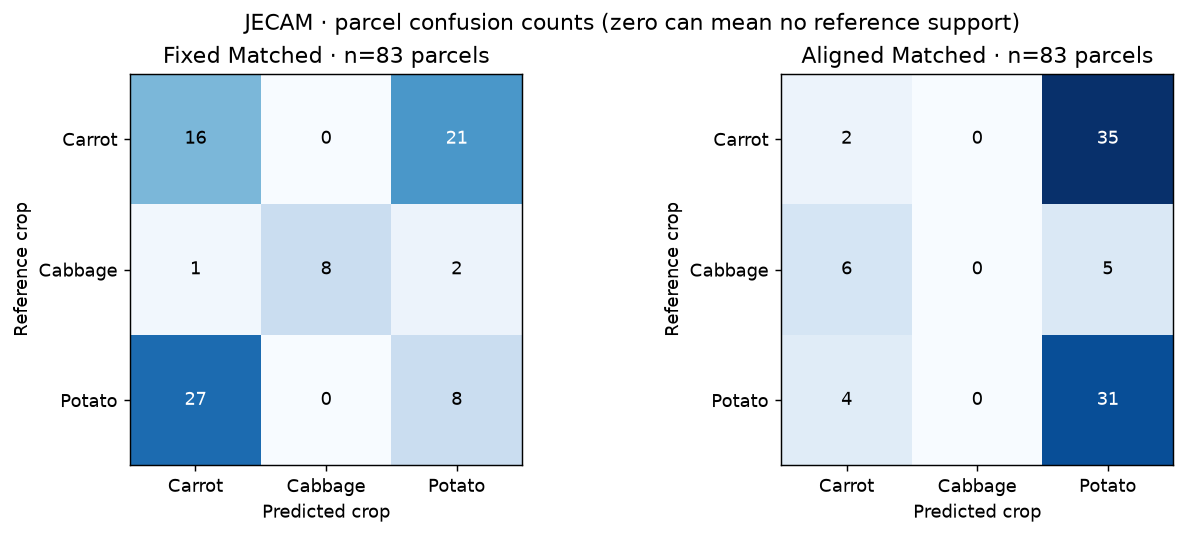

In [20]:
# Show JECAM's two matched confusion matrices. Rows are the reference crop.
import matplotlib.pyplot as plt

from crop_pipeline.visualization.demo import plot_confusion

cells = read_csv(batch1 / "confusion_matrices.csv")
figure = plot_confusion([
    {"test_population": "JECAM", "cohort": row["model"], "actual": row["actual"],
     "predicted": row["predicted"], "parcels": row["count"]}
    for row in cells
    if row["population"] == "jecam" and row["predictor"] == "model" and row["model"] in models[2:]
], "JECAM")
display(figure)
plt.close(figure)

In [21]:
oob = {(r["model"], r["method"]): r for r in read_csv(batch3 / "oob_summary.csv")}
error_rows = read_csv(batch3 / "campaign_crop_errors.csv")
table(("Model", "Pixel OOB error", "Whole-parcel OOB error", "Whole parcels scored / eligible",
       "Combined hard-vote disagreements"),
      [[model_name(model), f"{float(pixel['error_rate']):.1%}", f"{float(whole['error_rate']):.1%}",
        f"{whole['scored_units']} / {whole['eligible_units']}",
        f"{sum(int(r['hard_vote_winner_differs']) for r in selected)} / {sum(int(r['parcels']) for r in selected)}"]
       for model in models
       for pixel, whole, selected in [(oob[model, "pixel_oob"], oob[model, "whole_parcel_oob"],
           [r for r in error_rows if r["model"] == model and r["population"] == "combined"])]])
importance = read_csv(batch3 / "grouped_importance.csv")

def top_group(model, grouping):
    row = max((r for r in importance if r["model"] == model and r["grouping"] == grouping),
              key=lambda r: float(r["importance"]))
    return f"{row['group']} ({float(row['importance']):.1%})"

table(("Model", "Most important band or index", "Most important half-month bin"),
      [[model_name(model), top_group(model, "band_or_index"), top_group(model, "half_month_bin")]
       for model in models])

| Model | Pixel OOB error | Whole-parcel OOB error | Whole parcels scored / eligible | Combined hard-vote disagreements |
| --- | --- | --- | --- | --- |
| Fixed-full | 5.0% | 16.0% | 306 / 1076 | 26 / 341 |
| Aligned-full | 7.0% | 38.5% | 91 / 260 | 6 / 186 |
| Fixed-matched | 5.6% | 36.8% | 57 / 199 | 16 / 175 |
| Aligned-matched | 5.8% | 40.4% | 57 / 199 | 16 / 175 |

| Model | Most important band or index | Most important half-month bin |
| --- | --- | --- |
| Fixed-full | NDVI (16.2%) | 08 (16.9%) |
| Aligned-full | NDVI (15.6%) | 07 (16.0%) |
| Fixed-matched | NDMI (14.5%) | 01 (20.1%) |
| Aligned-matched | B4 (14.9%) | 07 (15.5%) |

## What the forest diagnostics tell us

| Check | What we did | Why it helps |
| --- | --- | --- |
| **Out-of-bag (OOB) error** | Rebuilt each tree’s training draw from the saved seeds and weights. Asked the trees that skipped a training pixel to predict it. A stricter check uses only trees that skipped every pixel in a field. | Gives an internal error check. A tree can skip one pixel and still see nearby pixels from that field, so pixel OOB can look optimistic. |
| **Grouped Gini importance** | Added up how much the fitted trees used each input to improve their splits, grouping once by band or index and again by half-month. | Shows what the fitted forest relied on. Similar predictors can share importance. |
| **Hard tree votes** | Each tree chooses one crop for a field after averaging its pixel probabilities. Compare the most-voted crop with the original choice from the forest’s mean probabilities. | Shows where a count of tree choices and the probability-based prediction disagree. The external scores keep the original predictions. |

**Examples.** Fixed-matched had **5.6% pixel OOB error**, but the stricter check reached just **57 of 199 training fields** and had **36.8% error** on those fields. Whole-field OOB had only about **1.4 trees per scored field** on average. NDMI was the largest band-or-index importance group for fixed-matched. The hard-vote winner differed from the original decision on **16 of 175** combined test fields for each matched model.

[Parcel diagnostics](../pipeline_outputs/testing/run_81a0d0a2812e_batch3/parcel_diagnostics.csv) · [OOB draws](../pipeline_outputs/testing/run_81a0d0a2812e_batch3/oob_tree_draws.csv) · [Grouped importance](../pipeline_outputs/testing/run_81a0d0a2812e_batch3/grouped_importance.csv)

In [22]:
from collections import Counter

trace = Counter(r["outcome"] for r in read_csv(batch3 / "training_cabbage_trace.csv"))
table(("FranceCrops training cabbage outcome", "Parcels"),
      [[label, trace[key]] for key, label in (
          ("both_full_windows", "Qualified for both full windows"),
          ("cycle_audit_no_usable_aligned_window", "Reached cycle review without usable aligned window"),
          ("no_cycle_selection_record", "Had no cycle-selection record"),
          ("aligned_full_only", "Qualified for aligned-full only"),
      )])

| FranceCrops training cabbage outcome | Parcels |
| --- | --- |
| Qualified for both full windows | 51 |
| Reached cycle review without usable aligned window | 117 |
| Had no cycle-selection record | 281 |
| Qualified for aligned-full only | 15 |

# Part 10 — Try three changes suggested by the errors

| Change | Why try it? | What we found on the same fields |
| --- | --- | --- |
| **Average the two forests’ probabilities equally** | Fixed and aligned got different fields right. Combining them might recover some errors. | The average scored **0.789** on locked validation, highest among these runs. Its external scores fell between the two originals on both pools. |
| **Use the middle value of each feature across a field’s pixels** | A field median can reduce the effect of an unusual pixel when several are available. | Aligned JECAM cabbage F1 rose from **0.000 to 0.696**. Aligned validation fell, and the combined macro-F1 gain was small. |
| **Choose a stronger complete green-up cycle** | A later, stronger rise might represent a more useful window. | It switched **10 retained test fields**. JECAM date overlap fell from **62 to 58**, and neither paired macro-F1 interval excluded zero. |

**Why keep the original models beside these results?** The alternatives address different problems and no one change led everywhere. The comparison uses an already examined test set, so these results identify candidates for a fresh test.

[Transfer follow-up report](../pipeline_outputs/testing/run_81a0d0a2812e_transfer_followups/report.md)

In [23]:
variants = (
    ("Original fixed", "fixed_matched_original"), ("Original aligned", "aligned_matched_original"),
    ("50/50 ensemble", "ensemble_50_50"), ("Fixed parcel medians", "fixed_matched_median"),
    ("Aligned parcel medians", "aligned_matched_median"),
    ("Aligned stronger-NDVI cycle", "aligned_matched_strongest_cycle"),
)
result = {(r["model"], r["population"]): r["macro_f1"] for r in read_csv(followups / "metrics.csv")
          if r["support_segment"] == "all"}
table(("Model", "Locked validation", "JECAM", "Combined"),
      [[label, *(f1(result[model, scope]) for scope in ("development", "jecam", "combined"))]
       for label, model in variants])

| Model | Locked validation | JECAM | Combined |
| --- | --- | --- | --- |
| Original fixed | 0.706 | 0.493 | 0.363 |
| Original aligned | 0.696 | 0.222 | 0.564 |
| 50/50 ensemble | 0.789 | 0.428 | 0.524 |
| Fixed parcel medians | 0.723 | 0.458 | 0.328 |
| Aligned parcel medians | 0.646 | 0.422 | 0.568 |
| Aligned stronger-NDVI cycle | 0.702 | 0.232 | 0.560 |

## What the error analysis changed

- **Summarize each field before classifying it.** Using the middle value of each feature across a field’s pixels helped the aligned model most on JECAM. Cabbage F1 rose from **0.000 to 0.696** and macro-F1 from **0.222 to 0.422**. It lowered the fixed model’s macro-F1 from **0.493 to 0.458**.
- **Combine the fixed and aligned predictions.** The windows got different fields right, so we tried averaging their crop probabilities. The average scored **0.428** on JECAM. The original fixed model scored **0.493**.
- **Change how we pick the green-up window.** Choosing the eligible window with the strongest rise in greenness moved aligned macro-F1 from **0.222 to 0.232**. The paired interval included zero, so the result was too uncertain to call an improvement. [Saved follow-up results](../pipeline_outputs/testing/run_81a0d0a2812e_transfer_followups/report.md)

**Why we still chose the 120-feature fixed Random Forest.** The error analysis gave us changes to try. The earlier feature comparison gave us the model we chose for the primary test. Adding 48 features that describe how vegetation changes over time brought the fixed forest to **0.558 macro-F1 on JECAM**, the highest score among the models compared in this walkthrough. It still needs work on potato, which had the lowest F1 (**0.358**). These results come from the same external benchmark, so a fresh set of fields would help confirm the choice. [Saved Random Forest shape comparison](../pipeline_outputs/testing/run_81a0d0a2812e_batch2/shape_comparison/report.md)


## What data and validation would help next?

| What limited the study | Evidence to collect or check next | Why it helps |
| --- | --- | --- |
| Few independent cabbage references and all training cabbage from one source | Add independently labelled head-cabbage fields from more regions and years. Record each field’s crop subtype, boundary, and source. Plan per-crop parcel targets before screening. | Expands the range of growing conditions and tests whether one source drove the result. |
| An annual declaration or survey date only partially describes the crop cycle | Record dated field occupancy, planting or harvest dates where available, and rotations. Compare those dates with the detected green-up and the selected image window. | Tests whether the window actually represents the labelled crop. |
| Empty bins, sparse clear dates, and some missing historical mask counts | Preserve pre-mask, clear, cloud/shadow, and other-rejection counts per acquisition. If a season crosses years, collect the adjacent-year observations. Apply the same quality checks and report how many extra fields qualify. | Distinguishes imagery gaps from masking loss and shows whether a longer archive improves coverage. |
| Small fields and visually unresolved error causes | Collect verified field boundaries and review dated imagery for a sample of correct and incorrect parcels. Record field size, usable pixel count, and visible evidence of mixed crops or shadow. | Tests whether boundary and coverage flags correspond to actual problems. |
| The external benchmark has already informed follow-up experiments | Reserve a fresh geographically separate three-crop test campaign or season. Check footprint overlap, lock parcel splits, model settings and the reporting scope before seeing its scores. Report per-crop F1, parcel counts, pixel support, and paired intervals when comparing models. | Provides an independent test of whether a change transfers beyond the previously examined benchmark. |

These steps describe next evidence needs for **external crop classification**. The saved study supplies the baseline for those tests.

# Part 11 — Save enough evidence to reproduce the study

**Batch 4** puts the dataset register, thesis methods and results, and the run manifest together. The manifest links the exact features, field splits, model files, predictions, and tables. It records **210 file checksums**. A checksum is a way to identify a file from the bytes it contains.

**Why verify the files?** A table is much easier to defend when we can trace it back to the same model and fields. The saved feature files match the history recorded at export. Two current preprocessing source files differ from the versions recorded then, so the external analysis starts from the saved features.

**Example.** We regenerated both sets of Batch 1 tables from the saved predictions and reproduced the archived results. The commands below show how to check the handoff and repeat the scoring.

[Thesis methods, results, limitations and rerun commands](../docs/classification_external_study.md) · [Final dataset register](../docs/classification_dataset_register.md) · [Run manifest](../pipeline_outputs/testing/run_81a0d0a2812e_batch4/study_manifest.json)

## Reproduce the external tables

From the repository root, with the saved data handoff available:

~~~bash
.venv/bin/python -m crop_pipeline.training.study_manifest verify \
  pipeline_outputs/testing/run_81a0d0a2812e_batch4/study_manifest.json

.venv/bin/python -m crop_pipeline.training.external_report \
  pipeline_outputs/testing/run_81a0d0a2812e \
  pipeline_outputs/testing/reproduced_external_report --revised-scope
~~~

Use a new reporting output directory. For the original scope, omit the revised-scope flag.

**Why start from the saved snapshots?** This reproduces the analysis from the feature bytes that were actually used. A preprocessing rebuild with today’s source code would be a separate provenance exercise.

# Part 12 — External deliverables and evidence

| Deliverable | Where the completed external work is recorded |
| --- | --- |
| **1. Prepare and assess the classification datasets** | [Final dataset register and crosswalk](../docs/classification_dataset_register.md) and [Collection 01](data_collection/01_external_reference_audit.ipynb). |
| **2. Implement preprocessing and feature engineering** | [Preprocessing 01–03](preprocessing/README.md), the [quality receipt](../pipeline_outputs/preprocessing/external_xxu0iz4o/quality/quality_stage_receipt.json), [window receipt](../pipeline_outputs/preprocessing/external_xxu0iz4o/windows/windows_stage_receipt.json), [feature receipt](../pipeline_outputs/preprocessing/external_xxu0iz4o/features/features_stage_receipt.json), and [sample counts and shortfalls](../pipeline_outputs/preprocessing/external_xxu0iz4o/features/usable_samples.csv). |
| **3. Build and evaluate the external classifier** | [Frozen model package](../pipeline_outputs/training/run_fa40f5d6bb31/models/models_stage.json), [Batch 1 results](../pipeline_outputs/testing/run_81a0d0a2812e_batch1_revised/report.md), [original-scope archive](../pipeline_outputs/testing/run_81a0d0a2812e_batch1/report.md), [Batch 2 feature comparisons](testing/03_model_comparisons.ipynb), and [tuning](training/03_matched_model_tuning.ipynb). |
| **5. Assess limitations and opportunities to improve** | [Batch 3 errors and forest diagnostics](testing/04_error_analysis_and_diagnostics.ipynb), [coverage losses](../pipeline_outputs/testing/run_81a0d0a2812e_batch3/imagery_coverage.csv), and [transfer experiments](../pipeline_outputs/testing/run_81a0d0a2812e_transfer_followups/report.md). |
| **6. Package the external study for submission** | [Thesis methods, results and limitations](../docs/classification_external_study.md), [run manifest](../pipeline_outputs/testing/run_81a0d0a2812e_batch4/study_manifest.json), and the verified reporting commands. Venue selection, sign-off, and submission are separate from packaging. |

Deliverable 4 belongs to the separate crop-suitability study.

**Why include this index?** It shows where to check each part of the study. For example, the usable sample ledger gives the counts behind the preprocessing claims, and the frozen model receipt identifies the exact models behind the test scores.

# Part 13 — How to explain the limits

| What to say | Example from our data |
| --- | --- |
| **Some crop groups were small.** | JECAM had 11 matched cabbage fields, three from Madagascar. Every JECAM crop fell below the pixel target. |
| **The pooled score depends on which fields were included.** | The reported scope changed after score review. The revised and complete original results are both saved, and both include JECAM. |
| **The training diagnostic and the external test answer different questions.** | A tree can skip one pixel and still see other pixels in that field. Use external parcel scores for transfer and OOB to inspect the forest. |
| **The results describe these fields and campaigns.** | Fixed-matched scored higher on JECAM, while aligned-matched scored higher on the revised combined pool. |

**Why keep this list?** It tells the reader which claims the data can support and what would need a new test.

| Term | Meaning |
| --- | --- |
| **Green-up** | A rise in the vegetation signal used to locate the start of a window. |
| **F1 / macro-F1** | F1 balances precision and recall for a crop. Macro-F1 gives the three crops equal weight. |
| **Paired interval** | A range for a score difference estimated by drawing the same fields for both models. |
| **Frozen model** | A fitted forest and its saved input rules, recorded before external scoring. |
| **SHA-256** | A checksum that checks whether a saved file has changed. |